# Credit Card Default Prediction

This notebook predicts whether a credit card client will **default on their payment next month**. It uses the `credit_card_clients_default` dataset from TabArena's BeyondArena collection: 30,000 clients described by 23 features.

It compares three classic tree-based models (**CatBoost**, **Random Forest**, **AdaBoost**), before and after hyperparameter tuning, with **Kumo-Tabular**, a pretrained tabular foundation model from NVIDIA.

## Setup

All imports are in the first cell:

- `pandas` / `numpy` for data handling and `matplotlib` for charts.
- `datasets` to load the data from Hugging Face.
- `catboost` and `sklearn.ensemble` for the three classic models.
- `hyperopt` for hyperparameter tuning.
- `sdm` and `torch` to run Kumo-Tabular.
- `sklearn.metrics` for the evaluation scores.

The second cell tells pandas to show every column of a table, instead of hiding the middle ones behind `...`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sdm
import torch
from catboost import CatBoostClassifier
from datasets import load_dataset
from hyperopt import STATUS_OK, fmin, hp, space_eval, tpe
from hyperopt.early_stop import no_progress_loss
from hyperopt.pyll import scope
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import cross_val_score, train_test_split

/home/sado/Projects/kumo-walkthrough/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
pd.set_option("display.max_columns", None)

## Data Loading

The BeyondArena repository holds 142 datasets. Loading it by name makes `datasets` read the metadata of all 142 before downloading anything, which is very slow. Loading this dataset's parquet file directly skips that step.

The download is cached in the `dataset/` folder, so later runs load instantly.

In [3]:
ds = load_dataset(
    "parquet",
    data_files="hf://datasets/TabArena/BeyondArena/credit_card_clients_default/*/dataset.parquet",
    cache_dir="dataset",
)
df = ds["train"].to_pandas()

## Exploratory Data Analysis

A first look at the raw data: the first rows, the shape (30,000 rows × 24 columns, which is 23 features plus the target) and summary statistics.

| Columns | Meaning |
|---|---|
| `LIMIT_BAL` | Credit limit |
| `SEX`, `EDUCATION`, `MARRIAGE`, `AGE` | Demographics |
| `PAY_0`, `PAY_2` – `PAY_6` | Repayment status in each of the last six months: −2 to 0 = paid on time or revolving credit, 1 – 8 = months of payment delay |
| `BILL_AMT1` – `BILL_AMT6` | Bill amount per month (can be negative after an overpayment) |
| `PAY_AMT1` – `PAY_AMT6` | Amount paid per month |
| `DefaultOnPaymentNextMonth` | Target: `Yes` or `No` |

`describe()` shows no missing values (the count is 30,000 in every column). The money columns have long right tails: their maximums are far above the 75th percentile.

In [4]:
df.head()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DefaultOnPaymentNextMonth
0,30000,1,2,2,25,0,0,0,0,0,0,8864,10062,11581,12580,13716,14828,1500,2000,1500,1500,1500,2000,No
1,150000,2,1,2,26,0,0,0,0,0,0,136736,125651,116684,101581,77741,77264,4486,4235,3161,2647,2669,2669,No
2,70000,2,3,1,32,0,0,0,0,0,0,70122,69080,68530,69753,70111,70212,2431,3112,3000,2438,2500,2554,No
3,130000,1,3,2,49,0,0,0,0,0,-1,20678,18956,16172,16898,11236,6944,1610,1808,7014,27,7011,4408,No
4,50000,2,2,2,36,0,0,0,0,0,2,94228,47635,42361,19574,20295,19439,2000,1500,1000,1800,0,1000,Yes


In [5]:
df.shape

(30000, 24)

In [6]:
df.describe()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000
mean,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,-0.266200,-0.291100,51223.330900,49179.075167,4.701315e+04,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567
std,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,1.133187,1.149988,73635.860576,71173.768783,6.934939e+04,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775
min,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,-165580.000000,-69777.000000,-1.572640e+05,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000
25%,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,3558.750000,2984.750000,2.666250e+03,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000
50%,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,22381.500000,21200.000000,2.008850e+04,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000
75%,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,67091.000000,64006.250000,6.016475e+04,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000
max,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,8.000000,8.000000,964511.000000,983931.000000,1.664089e+06,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000


## Feature Transformation

`cbrt_cols` replaces the money columns (`LIMIT_BAL`, `BILL_AMT*`, `PAY_AMT*`) with their cube root. This compresses the very large values, so they sit closer to the rest of the distribution.

The cube root is used instead of the square root because it also works on negative numbers: the square root of the negative `BILL_AMT` values would become `NaN`. The function returns a new DataFrame and doesn't change its input.

Tree-based models are barely affected by this kind of order-preserving transform. It matters more for linear or distance-based models.

In [7]:
def cbrt_cols(
    df: pd.DataFrame,
    column_names: list[str],
) -> pd.DataFrame:
    """Return a copy of ``df`` with the cube root applied to ``column_names``."""
    out = df.copy()
    out[column_names] = np.cbrt(out[column_names])
    return out

In [8]:
df = cbrt_cols(
    df=df,
    column_names=[
        "LIMIT_BAL",
        "BILL_AMT1",
        "BILL_AMT2",
        "BILL_AMT3",
        "BILL_AMT4",
        "BILL_AMT5",
        "BILL_AMT6",
        "PAY_AMT1",
        "PAY_AMT2",
        "PAY_AMT3",
        "PAY_AMT4",
        "PAY_AMT5",
        "PAY_AMT6",
    ],
)

In [9]:
df.head()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DefaultOnPaymentNextMonth
0,31.072325,1,2,2,25,0,0,0,0,0,0,20.695531,21.588780,22.624658,23.257349,23.937337,24.567494,11.447142,12.599210,11.447142,11.447142,11.447142,12.599210,No
1,53.132928,2,1,2,26,0,0,0,0,0,0,51.518233,50.086650,48.865660,46.659222,42.679243,42.591774,16.492497,16.178980,14.676016,13.833051,13.871269,13.871269,No
2,41.212853,2,3,1,32,0,0,0,0,0,0,41.236782,41.031505,40.922320,41.164322,41.234625,41.254416,13.446058,14.599787,14.422496,13.458952,13.572088,13.669112,No
3,50.657970,1,3,2,49,0,0,0,0,0,-1,27.447503,26.663402,25.288394,25.661287,22.397725,19.078164,11.720387,12.182399,19.142056,3.000000,19.139327,16.396351,No
4,36.840315,2,2,2,36,0,0,0,0,0,2,45.505091,36.250059,34.859573,26.950068,27.276984,26.887967,12.599210,11.447142,10.000000,12.164404,0.000000,10.000000,Yes


## Target Distribution

About **78%** of clients don't default and **22%** do.

This imbalance matters for evaluation: a model that always predicts `No` already reaches about 78% accuracy. That's why the metrics below include MCC, ROC AUC and per-class charts, not just accuracy.

In [10]:
df["DefaultOnPaymentNextMonth"].value_counts()

DefaultOnPaymentNextMonth
No     23364
Yes     6636
Name: count, dtype: int64

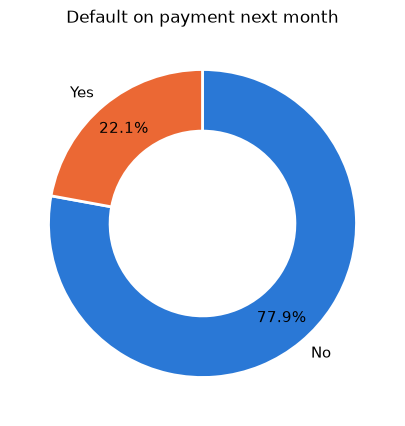

In [11]:
df["DefaultOnPaymentNextMonth"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    colors=["#2a78d6", "#eb6834"],
    startangle=90,
    counterclock=False,
    pctdistance=0.8,
    wedgeprops={"width": 0.4, "edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 11},
    title="Default on payment next month",
    ylabel="",
    figsize=(5, 5),
);

## Preparing the Training Data

1. The target is mapped from `Yes` / `No` to `1` / `0`.
2. The target is split off into `y`, and the features into `X`. Both are NumPy arrays from here on, so the column names are not kept.
3. 20% of the rows are held out as a test set. `stratify=y` keeps the 78 / 22 class ratio the same in the training and test sets.

No `random_state` is set, so the split, and with it every score, changes slightly on each run.

In [12]:
df["DefaultOnPaymentNextMonth"] = df["DefaultOnPaymentNextMonth"].map({
    "Yes": 1,
    "No": 0,
})

In [13]:
y = df["DefaultOnPaymentNextMonth"].values
del df["DefaultOnPaymentNextMonth"]
X = df.values
del df

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
)

## Evaluation Metrics

`calculate_metrics` scores a model's predictions on the test set:

- **acc**: share of correct predictions.
- **precision / recall / f1**: averaged over both classes, weighted by class size. Because `No` is the larger class, it dominates these averages; weighted recall is always equal to accuracy.
- **mcc** (Matthews correlation coefficient): one score from −1 to 1 that stays fair under class imbalance. 0 means no better than chance.
- **roc_auc**: computed from predicted probabilities. It measures how well the model ranks defaulters above non-defaulters, regardless of the 0.5 cutoff. 0.5 means random, 1 means perfect.
- **tn / fp / fn / tp**: the confusion-matrix counts, used by the charts at the end.

`results` collects the scores of every model under its own key.

In [15]:
def calculate_metrics(
    y_true: list[float],
    y_pred: list[float],
    y_prob: list[float],
) -> dict[str, float]:
    """# Calculate Metrics."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        "acc": accuracy_score(y_true, y_pred),
        "precision": precision_score(
            y_true,
            y_pred,
            average="weighted",
        ),
        "recall": recall_score(
            y_true,
            y_pred,
            average="weighted",
        ),
        "f1": f1_score(
            y_true,
            y_pred,
            average="weighted",
        ),
        "mcc": matthews_corrcoef(
            y_true,
            y_pred,
        ),
        "roc_auc": roc_auc_score(
            y_true,
            y_prob,
        ),
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp,
    }

In [16]:
results = {}

## Baseline Models

Each model is first trained with its default settings, as a reference point for tuning.

Each training cell overwrites `model` and `y_pred`, and the cell after it stores the scores, so run each pair in order.

### CatBoost

Gradient-boosted decision trees. Each new tree corrects the errors of the trees before it. CatBoost usually performs well on tabular data with its default settings. `verbose=False` hides its training log.

In [17]:
model = CatBoostClassifier(verbose=False)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [18]:
results["catboost_base"] = calculate_metrics(
    y_test,
    y_pred,
    model.predict_proba(X_test)[:, 1],
)

### Random Forest

Many independent decision trees, each trained on a random sample of rows and features. The forest's prediction is the average vote of its trees.

In [19]:
model = RandomForestClassifier()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [20]:
results["rf_base"] = calculate_metrics(
    y_test,
    y_pred,
    model.predict_proba(X_test)[:, 1],
)

### AdaBoost

Boosting with very small trees (one split each, by default). After each tree, the rows it got wrong get more weight, so the next tree focuses on them.

In [21]:
model = AdaBoostClassifier()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [22]:
results["ada_base"] = calculate_metrics(
    y_test,
    y_pred,
    model.predict_proba(X_test)[:, 1],
)

## Hyperparameter Tuning

Hyperopt searches for better settings for each model. It uses TPE (Tree-structured Parzen Estimator), which picks the next settings to try based on how the earlier ones scored.

Each model needs three parts: a search space, an objective function and a runner.

### Search Spaces

Each dictionary defines the range hyperopt may try for every parameter:

- `scope.int(hp.quniform(...))`: whole numbers in a range, such as the number of trees.
- `hp.loguniform(...)`: a log scale, so small learning rates like 0.01 are searched as thoroughly as large ones.
- `hp.uniform(...)`: any value in a range.
- `hp.choice(...)`: one option from a list.

The class-weight options let CatBoost and Random Forest give more weight to the smaller `Yes` class.

In [23]:
catboost_space = {
    "iterations": scope.int(hp.quniform("iterations", 200, 1500, 100)),
    "learning_rate": hp.loguniform("learning_rate", np.log(0.01), np.log(0.3)),
    "depth": scope.int(hp.quniform("depth", 4, 10, 1)),
    "l2_leaf_reg": hp.loguniform("l2_leaf_reg", np.log(1), np.log(10)),
    "bagging_temperature": hp.uniform("bagging_temperature", 0, 1),
    "auto_class_weights": hp.choice("auto_class_weights", [None, "Balanced"]),
}

In [24]:
rf_space = {
    "n_estimators": scope.int(hp.quniform("n_estimators", 100, 1000, 50)),
    "max_depth": hp.choice("max_depth", [None, 5, 10, 20, 30]),
    "min_samples_split": scope.int(hp.quniform("min_samples_split", 2, 20, 1)),
    "min_samples_leaf": scope.int(hp.quniform("min_samples_leaf", 1, 10, 1)),
    "max_features": hp.choice("max_features", ["sqrt", "log2", None]),
    "class_weight": hp.choice("class_weight", [None, "balanced"]),
}

In [25]:
ada_space = {
    "n_estimators": scope.int(hp.quniform("n_estimators", 50, 500, 25)),
    "learning_rate": hp.loguniform("learning_rate", np.log(0.01), np.log(2)),
}

### Objective Functions

Each objective builds a model with the settings hyperopt proposes and scores it with **3-fold cross-validated ROC AUC on the training set**. The test set stays untouched during tuning, so the final test scores remain a fair comparison.

Hyperopt minimizes its target, so the score is returned as a negative `loss`.

In [26]:
def catboost_objective(params: dict) -> dict:
    """Return the negative 3-fold CV ROC AUC of CatBoost with ``params``."""
    model = CatBoostClassifier(**params, verbose=False)
    score = cross_val_score(model, X_train, y_train, cv=3, scoring="roc_auc").mean()
    return {"loss": -score, "status": STATUS_OK}

In [27]:
def rf_objective(params: dict) -> dict:
    """Return the negative 3-fold CV ROC AUC of RandomForest with ``params``."""
    model = RandomForestClassifier(**params, n_jobs=-1)
    score = cross_val_score(model, X_train, y_train, cv=3, scoring="roc_auc").mean()
    return {"loss": -score, "status": STATUS_OK}

In [28]:
def ada_objective(params: dict) -> dict:
    """Return the negative 3-fold CV ROC AUC of AdaBoost with ``params``."""
    model = AdaBoostClassifier(**params)
    score = cross_val_score(model, X_train, y_train, cv=3, scoring="roc_auc").mean()
    return {"loss": -score, "status": STATUS_OK}

### Running the Search

Each runner:

1. Tries up to 100 settings with `fmin`. `no_progress_loss(20)` stops early once 20 trials in a row fail to beat the best score, and the fixed `rstate` makes the search repeatable.
2. Converts the best result to real parameter values with `space_eval` (for `hp.choice`, `fmin` returns list positions, not values).
3. Retrains that model on the full training set and stores its test scores under `*_tuned`.

On CPU, each search takes roughly 3 – 20 minutes.

In [29]:
best = fmin(
    catboost_objective,
    catboost_space,
    algo=tpe.suggest,
    max_evals=100,
    early_stop_fn=no_progress_loss(20),
    rstate=np.random.default_rng(42),
)
model = CatBoostClassifier(**space_eval(catboost_space, best), verbose=False)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
results["catboost_tuned"] = calculate_metrics(
    y_test,
    y_pred,
    model.predict_proba(X_test)[:, 1],
)

 67%|██████▋   | 67/100 [18:56<09:19, 16.96s/trial, best loss: -0.7837620587674626]


In [30]:
best = fmin(
    rf_objective,
    rf_space,
    algo=tpe.suggest,
    max_evals=100,
    early_stop_fn=no_progress_loss(20),
    rstate=np.random.default_rng(42),
)
model = RandomForestClassifier(**space_eval(rf_space, best), n_jobs=-1)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
results["rf_tuned"] = calculate_metrics(
    y_test,
    y_pred,
    model.predict_proba(X_test)[:, 1],
)

 20%|██        | 20/100 [02:36<10:25,  7.82s/trial, best loss: -0.7818573351506846]


In [31]:
best = fmin(
    ada_objective,
    ada_space,
    algo=tpe.suggest,
    max_evals=100,
    early_stop_fn=no_progress_loss(20),
    rstate=np.random.default_rng(42),
)
model = AdaBoostClassifier(**space_eval(ada_space, best))
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
results["ada_tuned"] = calculate_metrics(
    y_test,
    y_pred,
    model.predict_proba(X_test)[:, 1],
)

 67%|██████▋   | 67/100 [19:26<09:34, 17.41s/trial, best loss: -0.7721733793979083]


## Kumo-Tabular

[Kumo-Tabular](https://huggingface.co/nvidia/Kumo-Tabular) is a pretrained tabular foundation model from NVIDIA. It isn't trained or tuned on this data. Instead it **learns in context**: the labeled training rows are passed in as examples together with the test rows, and it predicts the test rows in one pass.

- The arrays are turned back into DataFrames with generic column names (`f0` – `f22`) and converted to `sdm.TableTensor`s. `infer_stypes` marks the target as categorical, which makes this a classification task.
- `num_estimators=4` averages four ensemble members. More members are usually slightly better but slower: on CPU, each one takes about 6 – 7 minutes here.
- The float16 speed-up (`autocast`) only switches on with an NVIDIA GPU.
- The output is a table of class probabilities. The predicted class is the column with the highest probability, and the `"1"` column (probability of default) is used for ROC AUC.

In [32]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
columns = [f"f{i}" for i in range(X_train.shape[1])]

train = pd.DataFrame(X_train, columns=columns).assign(target=y_train)
stypes = sdm.infer_stypes(train, overrides={"target": "categorical"})
train_table = sdm.TableTensor.from_pandas(df=train, stypes=stypes, device=device)
test_table = sdm.TableTensor.from_pandas(
    df=pd.DataFrame(X_test, columns=columns),
    stypes={col: stypes[col] for col in columns},
    device=device,
)

model = sdm.models.KumoTabular(task="classification", device=device)
with torch.amp.autocast(
    device.type,
    dtype=torch.float16,
    enabled=device.type == "cuda",
):
    probs = model(
        x_context=train_table.drop_columns("target"),
        y_context=train_table[:, "target"],
        x_query=test_table,
        num_estimators=4,
    )
y_pred = probs.to_pandas().idxmax(axis=1).astype(int).to_numpy()

In [33]:
results["kumo"] = calculate_metrics(
    y_test,
    y_pred,
    probs.to_pandas()["1"].to_numpy(),
)

## Results

The scores are saved to `results.json` so they survive a kernel restart, then compared in a table and charts.

In [34]:
pd.DataFrame(results).to_json("results.json", indent=4)

### Score Table

One row per model. Darker cells are better within each metric column.

In [35]:
scores = pd.DataFrame(results).T
metric_names = ["acc", "precision", "recall", "f1", "mcc", "roc_auc"]
scores[metric_names].style.background_gradient(cmap="Blues", axis=0).format("{:.3f}")

,acc,precision,recall,f1,mcc,roc_auc
catboost_base,0.822,0.805,0.822,0.801,0.408,0.785
rf_base,0.817,0.798,0.817,0.796,0.390,0.760
ada_base,0.821,0.805,0.821,0.795,0.396,0.773
catboost_tuned,0.823,0.806,0.823,0.801,0.409,0.789
rf_tuned,0.823,0.807,0.823,0.801,0.409,0.781
ada_tuned,0.819,0.802,0.819,0.794,0.390,0.779
kumo,0.824,0.809,0.824,0.804,0.418,0.794


### Accuracy

Test accuracy per model. The dashed line is the accuracy of always predicting `No` (about 78%). Every model sits only a few points above it, which is why accuracy alone isn't a good way to compare them here.

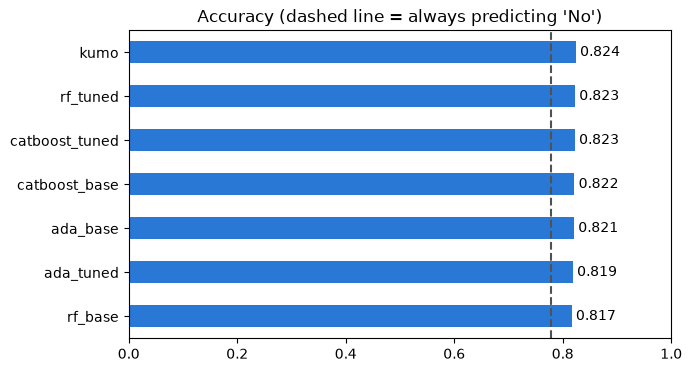

In [36]:
ax = scores["acc"].sort_values().plot(
    kind="barh",
    color="#2a78d6",
    xlim=(0, 1),
    title="Accuracy (dashed line = always predicting 'No')",
    figsize=(7, 4),
)
ax.axvline((y_test == 0).mean(), color="#52514e", linestyle="--")
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3);

### MCC

MCC takes both classes into account, so it's the fairest single score for this imbalanced data. 0 means no better than random guessing, 1 means perfect.

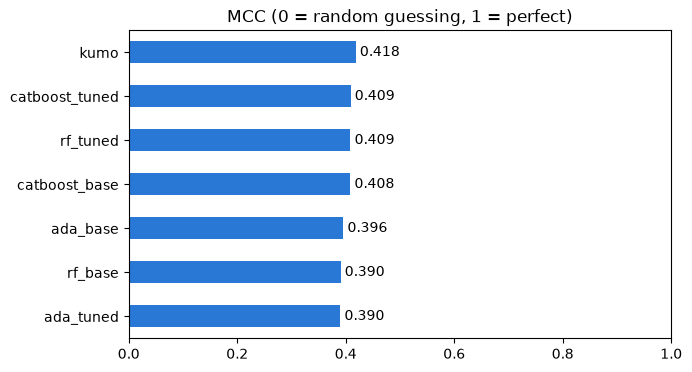

In [37]:
ax = scores["mcc"].sort_values().plot(
    kind="barh",
    color="#2a78d6",
    xlim=(0, 1),
    title="MCC (0 = random guessing, 1 = perfect)",
    figsize=(7, 4),
)
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3);

### ROC AUC

ROC AUC uses the predicted probabilities, not the final yes/no decision. It shows how well each model ranks defaulters above non-defaulters at any cutoff. The dashed line at 0.5 is random guessing.

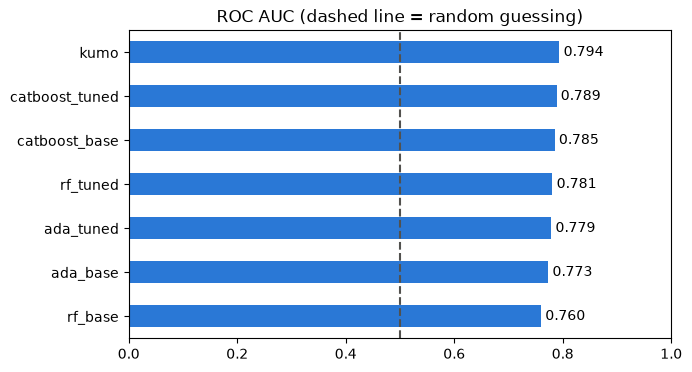

In [38]:
ax = scores["roc_auc"].sort_values().plot(
    kind="barh",
    color="#2a78d6",
    xlim=(0, 1),
    title="ROC AUC (dashed line = random guessing)",
    figsize=(7, 4),
)
ax.axvline(0.5, color="#52514e", linestyle="--")
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3);

### Effect of Tuning

MCC of each classic model with default settings (`base`) and after hyperopt (`tuned`). Kumo-Tabular has no tuned version, so it isn't shown.

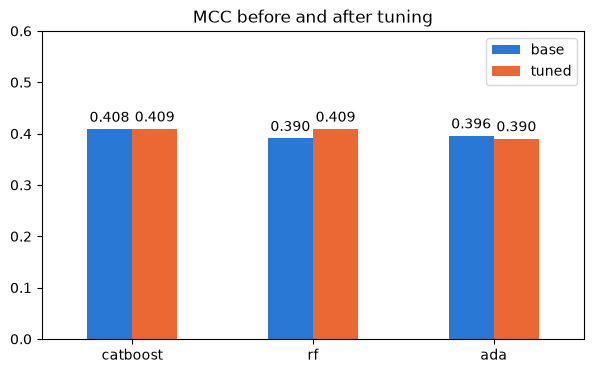

In [39]:
models = ["catboost", "rf", "ada"]
ax = pd.DataFrame(
    {
        "base": [results[f"{m}_base"]["mcc"] for m in models],
        "tuned": [results[f"{m}_tuned"]["mcc"] for m in models],
    },
    index=models,
).plot(
    kind="bar",
    color=["#2a78d6", "#eb6834"],
    ylim=(0, 0.6),
    rot=0,
    title="MCC before and after tuning",
    figsize=(7, 4),
)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3);

### Finding Defaulters

How each model handles the smaller `Yes` class, which the weighted metrics hide:

- **caught (recall)**: share of real defaulters the model flagged.
- **flagged correctly (precision)**: share of `Yes` predictions that were real defaulters.

All models use a 0.5 probability cutoff. Lowering it would catch more defaulters, at the cost of more false alarms.

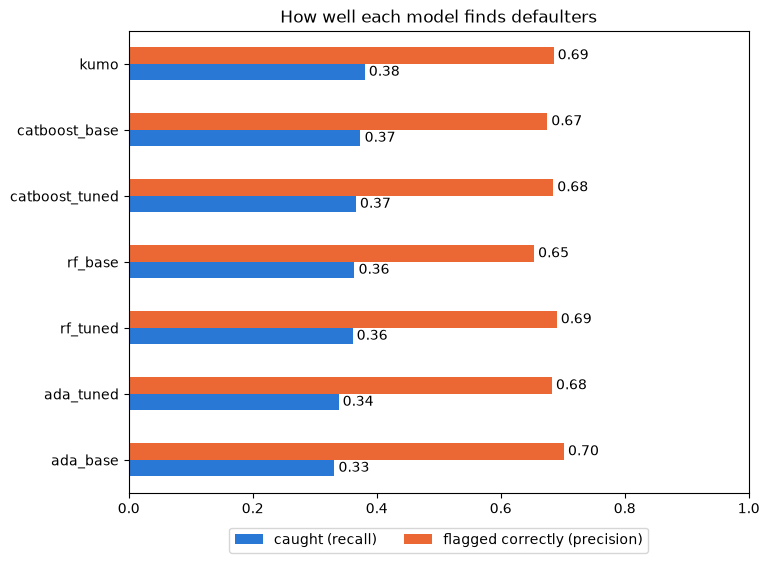

In [40]:
defaulters = pd.DataFrame(
    {
        "caught (recall)": scores["tp"] / (scores["tp"] + scores["fn"]),
        "flagged correctly (precision)": scores["tp"] / (scores["tp"] + scores["fp"]),
    },
).sort_values("caught (recall)")
ax = defaulters.plot(
    kind="barh",
    color=["#2a78d6", "#eb6834"],
    xlim=(0, 1),
    title="How well each model finds defaulters",
    figsize=(8, 6),
)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.06), ncols=2);

### Confusion Matrices

Rows are the actual class, columns the predicted class:

- **Top left**: non-defaulters correctly predicted as `No`.
- **Top right**: false alarms (predicted `Yes`, actually `No`).
- **Bottom left**: missed defaulters (predicted `No`, actually `Yes`), usually the most costly error for a lender.
- **Bottom right**: defaulters correctly caught.

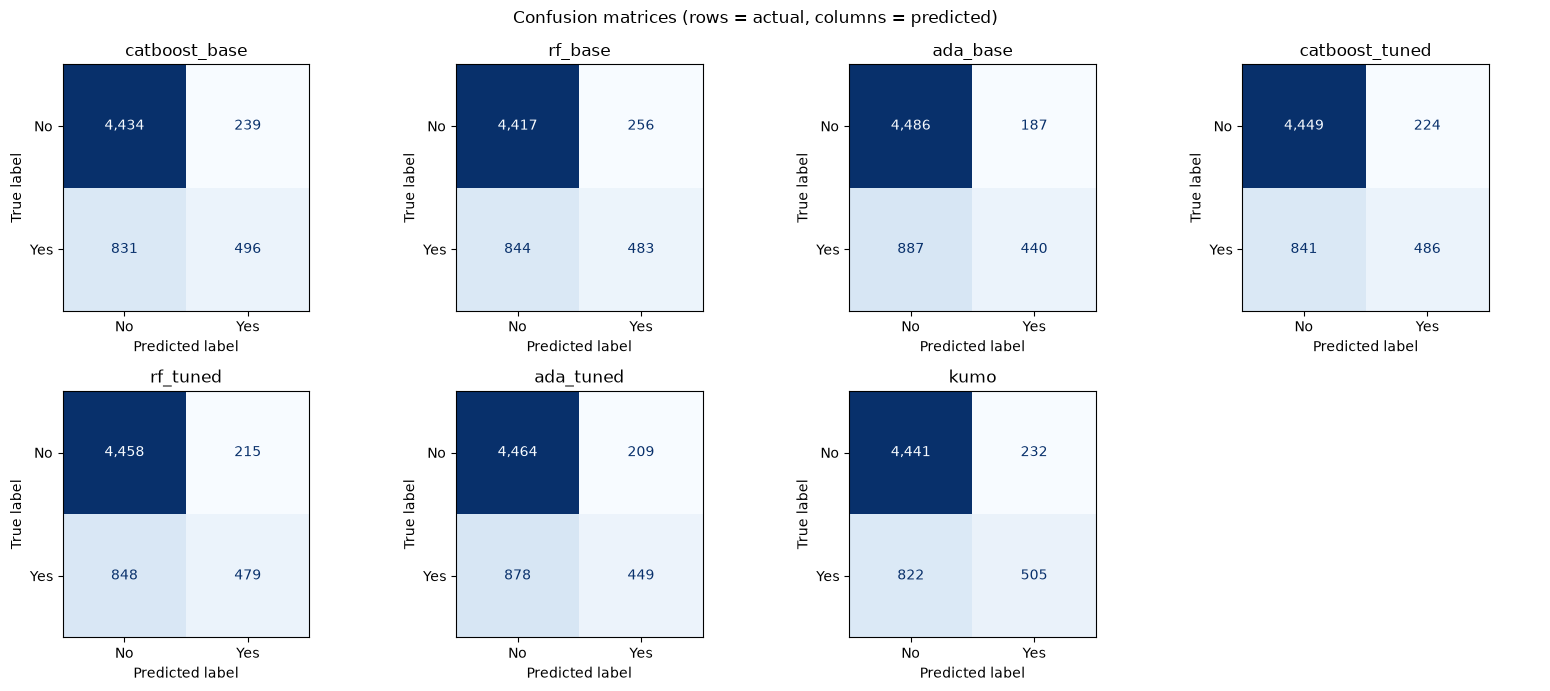

In [41]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, (name, row) in zip(axes.flat, scores.iterrows(), strict=False):
    cm = row[["tn", "fp", "fn", "tp"]].to_numpy(dtype=int).reshape(2, 2)
    ConfusionMatrixDisplay(cm, display_labels=["No", "Yes"]).plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format=",",
    )
    ax.set_title(name)
for ax in axes.flat[len(scores):]:
    ax.axis("off")
fig.suptitle("Confusion matrices (rows = actual, columns = predicted)")
fig.tight_layout()

## Key Findings

From the latest run. Scores shift slightly between runs, because the train/test split has no fixed seed.

- **Kumo-Tabular scored best on every metric** (MCC 0.418, ROC AUC 0.794), with no training or tuning.
- **The differences are small.** All seven models are within 0.007 accuracy and 0.028 MCC of each other.
- **Tuning helped little.** MCC: Random Forest +0.019, CatBoost +0.001, AdaBoost −0.006. ROC AUC improved for all three tuned models, most for Random Forest (0.760 → 0.781).
- **Most defaulters are missed.** At the 0.5 cutoff, the models catch only 33 – 38% of real defaulters, while about two thirds of their `Yes` predictions are correct. Lowering the cutoff is the most promising next step if catching defaulters matters more than avoiding false alarms.